In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from beta_evidence_field import (OccupancyField, OccupancyObservation, OccupancyPrior)
from tools.plotting      import configure_plots, plot_observation_2d, plot_field_2d

configure_plots()

c:\Code\beta-evidence-fields\.pixi\envs\default\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SPATIAL_DIMENSIONS = (-1.5, -1.5, 4.0, 4.0)
SPATIAL_RESOLUTION = 100

ANGLE_OFFSET       = np.deg2rad(45)
ANGLE_RANGE        = (np.deg2rad(-30), np.deg2rad(30))
ANGLE_RESOLUTION   = 100
OBSERVATION_RANGE  = 3.0

In [3]:
field = OccupancyField.from_yaml("../config/example_2d_config.yaml")

observation = OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                   direction = np.array([np.cos(ANGLE_OFFSET), np.sin(ANGLE_OFFSET)]),
                                   range     = OBSERVATION_RANGE,
                                   returned  = True,
                                   time      = 0.0)

obs = field.add([observation])

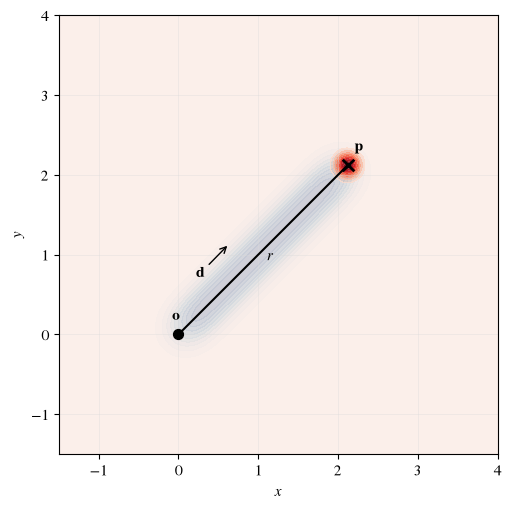

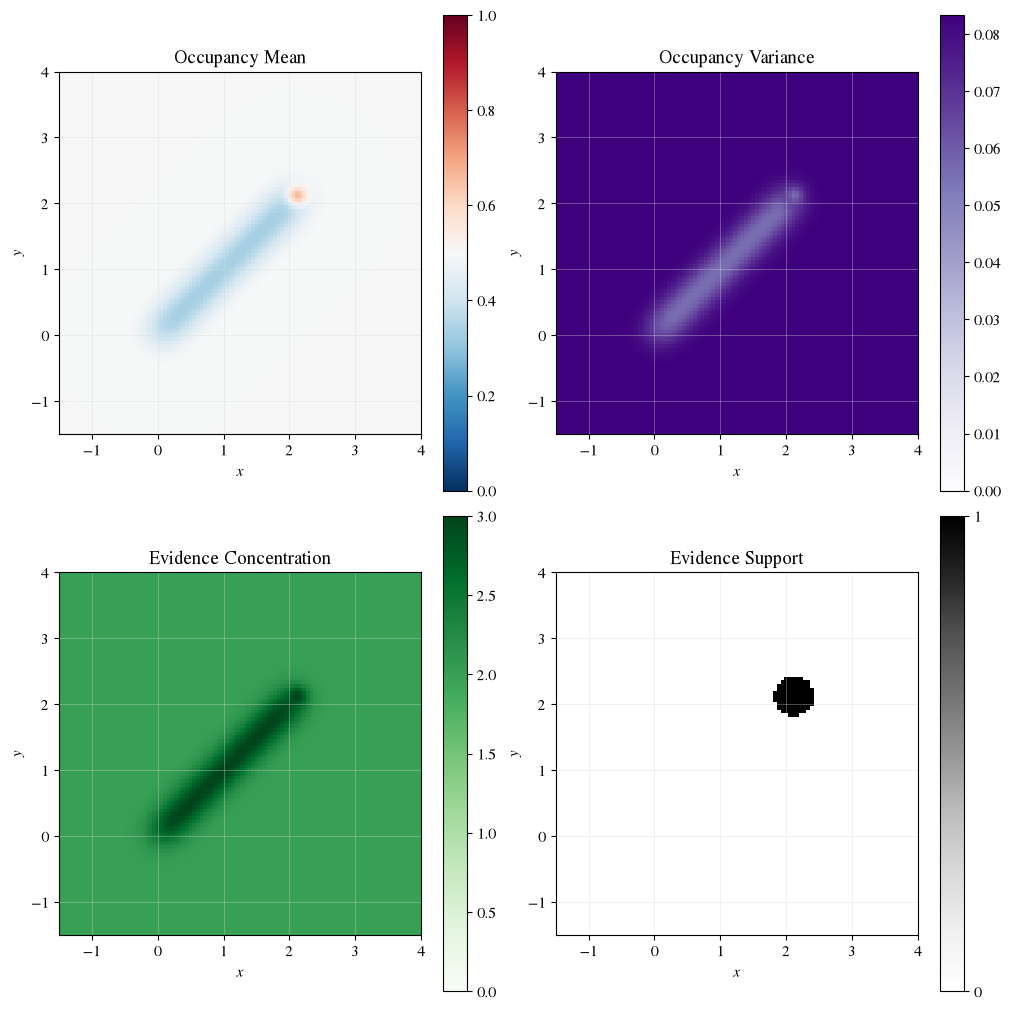

In [4]:
x = np.linspace(SPATIAL_DIMENSIONS[0], SPATIAL_DIMENSIONS[2], SPATIAL_RESOLUTION)
y = np.linspace(SPATIAL_DIMENSIONS[1], SPATIAL_DIMENSIONS[3], SPATIAL_RESOLUTION)

X, Y = np.meshgrid(x, y, indexing = "ij")

points = np.column_stack((X.ravel(),
                          Y.ravel()))

surface = field.surface_kernel.evaluate(points = points, 
                                        centre = observation.endpoint).reshape(X.shape)

free    = field.free_kernel.convolve_line(points = points, 
                                          start  = observation.origin, 
                                          end    = observation.endpoint).reshape(X.shape)

plot    = plot_observation_2d(X           = X,
                              Y           = Y,
                              surface     = surface,
                              free        = free,
                              observation = observation)

query   = field.query(points = points,
                      time   = 0.0)

plot    = plot_field_2d(X     = X,
                        Y     = Y,
                        query = query)

Generating observations: 100%|██████████| 100/100 [00:00<00:00, 55620.00it/s]


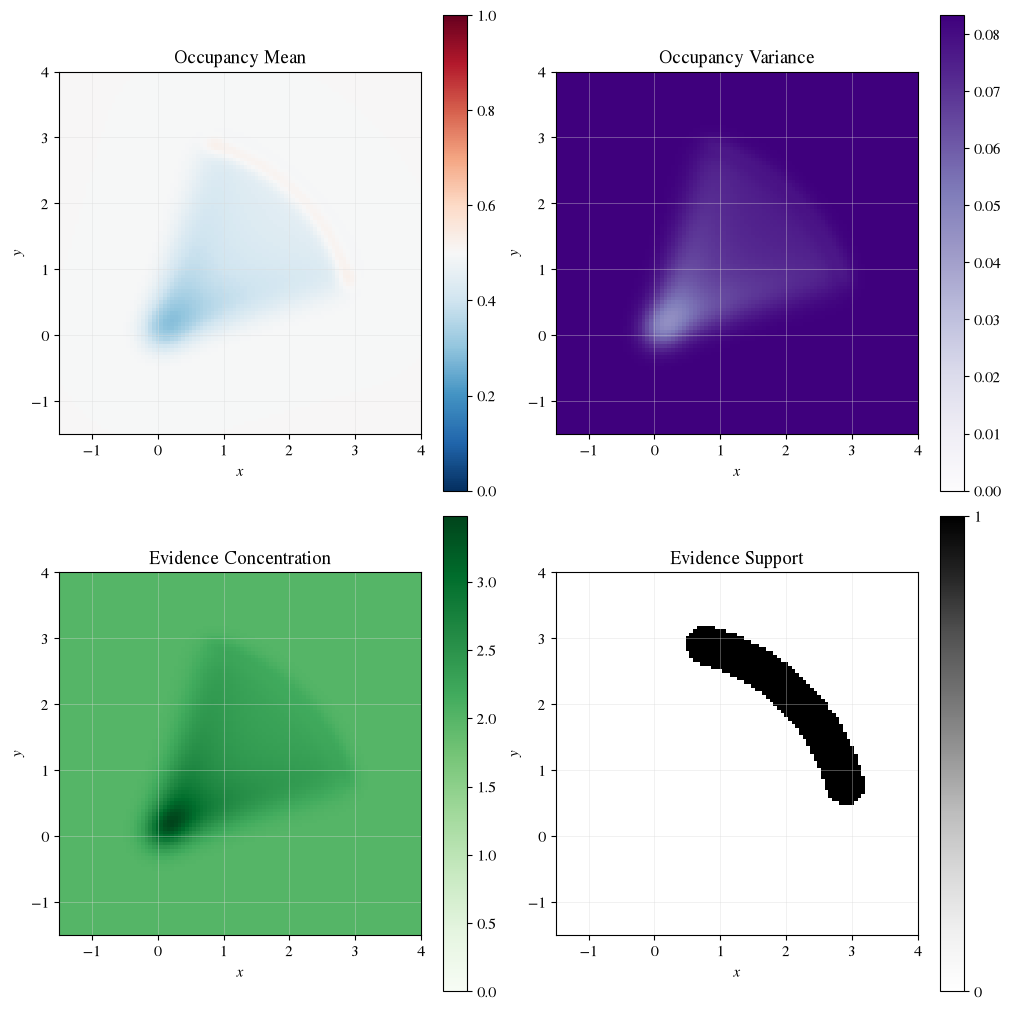

In [5]:
angles       = np.linspace(ANGLE_RANGE[0], ANGLE_RANGE[1], ANGLE_RESOLUTION)
observations = []

for angle in tqdm(angles, desc = "Generating observations"):
    observations.append(OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                             direction = np.array([np.cos(angle + ANGLE_OFFSET), np.sin(angle + ANGLE_OFFSET)]),
                                             range     = OBSERVATION_RANGE,
                                             returned  = True,
                                             time      = 0.0))


field.clear()
obs = field.add(observations)

x = np.linspace(SPATIAL_DIMENSIONS[0], SPATIAL_DIMENSIONS[2], SPATIAL_RESOLUTION)
y = np.linspace(SPATIAL_DIMENSIONS[1], SPATIAL_DIMENSIONS[3], SPATIAL_RESOLUTION)

X, Y = np.meshgrid(x, y)

points = np.column_stack((X.ravel(), Y.ravel()))

query   = field.query(points = points,
                      time   = 0.0)

plot    = plot_field_2d(X     = X,
                        Y     = Y,
                        query = query)